# text2color

Учим BERT по короткой зарисовке определять цвет, который возникает в голове.

## Импорты

In [1]:
import os
# Локальный токен Hugging Face просрочен, а все нужные модели публичные:
# просим библиотеку не отправлять токен, иначе загрузка падает с ошибкой.
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"

import html
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from datasets import Dataset
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments

## Данные

Читаем обучающий датасет: колонка `text` — зарисовка, колонка `color` — цвет.

In [2]:
df = pd.read_csv("data/data.csv")
df

,text,color,type
0,"Солнце медленно опускается в море, по воде беж...",оранжевый,сцена
1,"Раннее утро, над рекой стелется густой туман, ...",серый,сцена
2,"Мы шли по лесу после дождя, вокруг пахло мхом ...",зелёный,сцена
3,"Ночной город светится тысячами окон, внизу мед...",синий,сцена
4,"Всё поле покрыто свежим снегом, и на нём нет н...",белый,сцена
...,...,...,...
1495,"Рыбак сидит у причала с удочкой, но клёва нет,...",серый,эмоция
1496,"Экзамен по вождению сдан с первого раза, и рук...",белый,эмоция
1497,"Голос в трубке говорит всё те же слова, и она ...",серый,эмоция
1498,"Растения на балконе ожили после полива, и она ...",белый,эмоция


Сколько примеров каждого цвета:

In [3]:
df["color"].value_counts()

color
оранжевый     150
серый         150
зелёный       150
синий         150
белый         150
красный       150
жёлтый        150
голубой       150
коричневый    150
фиолетовый    150
Name: count, dtype: int64

Каждая зарисовка — либо **сцена** (цвет следует из предметов: клубника, туман), либо **эмоция** (цвет задаётся чувством: злость → красный). Колонка `type`. Сколько тех и других для каждого цвета:

In [4]:
df.groupby(["color", "type"]).size().unstack()

type,сцена,эмоция
color,,
белый,76,74
голубой,76,74
жёлтый,76,74
зелёный,76,74
коричневый,76,74
красный,76,74
оранжевый,76,74
серый,75,75
синий,76,74


## Словарь меток

Модель работает с числами, а не со словами. Поэтому каждому цвету даём номер:
- `label2id` — цвет → номер (для обучения);
- `id2label` — номер → цвет (чтобы перевести ответ модели обратно в цвет).

In [5]:
colors = ["красный", "оранжевый", "жёлтый", "зелёный", "голубой",
          "синий", "фиолетовый", "коричневый", "белый", "серый"]

label2id = {color: i for i, color in enumerate(colors)}
id2label = {i: color for i, color in enumerate(colors)}

label2id

{'красный': 0,
 'оранжевый': 1,
 'жёлтый': 2,
 'зелёный': 3,
 'голубой': 4,
 'синий': 5,
 'фиолетовый': 6,
 'коричневый': 7,
 'белый': 8,
 'серый': 9}

Добавляем в таблицу колонку `label` с номером цвета:

In [6]:
df["label"] = df["color"].map(label2id)
df.head()

,text,color,type,label
0,"Солнце медленно опускается в море, по воде беж...",оранжевый,сцена,1
1,"Раннее утро, над рекой стелется густой туман, ...",серый,сцена,9
2,"Мы шли по лесу после дождя, вокруг пахло мхом ...",зелёный,сцена,3
3,"Ночной город светится тысячами окон, внизу мед...",синий,сцена,5
4,"Всё поле покрыто свежим снегом, и на нём нет н...",белый,сцена,8


Проверка: у каждого примера должен быть номер. Если цвет написан с опечаткой, `map` вернёт пустое значение.

In [7]:
df["label"].isna().sum()

np.int64(0)

## Разбиение на train, validation и test

| Выборка | Доля | Для чего |
|---|---|---|
| **train** | 70% | модель учится на этих примерах |
| **validation** | 15% | следим за обучением и выбираем лучшую эпоху |
| **test** | 15% | одна честная оценка в самом конце |

Почему validation отдельно от test: если выбирать настройки (эпохи, learning rate) по тесту, мы незаметно подгоняем модель под эти конкретные примеры, и оценка на тесте становится завышенной.

`train_test_split` делит только на две части, поэтому вызываем его дважды: сначала отрезаем test, потом из остатка — validation.

**Стратификация** — по паре «цвет + тип»: в каждой выборке будет одинаковая доля каждого цвета, а внутри цвета — поровну сцен и эмоций. Иначе, например, в тест могли бы попасть почти одни эмоции, и сравнение было бы нечестным.

In [8]:
df["group"] = df["color"] + " / " + df["type"]

train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    stratify=df["group"],
    random_state=42,
)

# 0.15 / 0.85 — чтобы validation тоже была 15% от всех данных
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    stratify=train_val_df["group"],
    random_state=42,
)

print("train:      ", len(train_df))
print("validation: ", len(val_df))
print("test:       ", len(test_df))

train:       1049
validation:  226
test:        225


Сколько примеров каждого цвета в каждой выборке:

In [9]:
counts = pd.DataFrame({
    "train": train_df["color"].value_counts(),
    "validation": val_df["color"].value_counts(),
    "test": test_df["color"].value_counts(),
}).loc[colors]
counts

,train,validation,test
color,,,
красный,105,23,22
оранжевый,105,22,23
жёлтый,105,22,23
зелёный,104,23,23
голубой,105,23,22
синий,104,23,23
фиолетовый,106,22,22
коричневый,104,23,23
белый,105,23,22


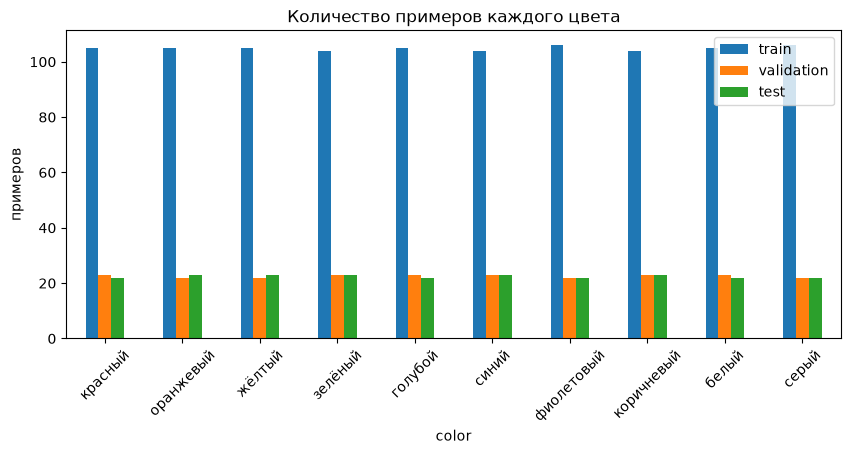

In [10]:
counts.plot.bar(figsize=(10, 4), title="Количество примеров каждого цвета")
plt.ylabel("примеров")
plt.xticks(rotation=45)
plt.show()

И сцены/эмоции в каждой выборке:

In [11]:
pd.DataFrame({
    "train": train_df["type"].value_counts(),
    "validation": val_df["type"].value_counts(),
    "test": test_df["type"].value_counts(),
})

,train,validation,test
type,,,
сцена,527,116,115
эмоция,522,110,110


## Токенизатор

Модель не читает буквы. Токенизатор режет текст на **токены** (слова или кусочки слов) и заменяет каждый на номер из своего **словаря**. Каждая модель понимает только свой токенизатор: номер 5000 у одной модели и у другой означает разные кусочки текста.

Наша модель — `ai-forever/ruBert-base`, BERT для русского языка (12 энкодер-блоков, ~178M параметров). Загрузим её токенизатор.

In [12]:
MODEL_NAME = "ai-forever/ruBert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("размер словаря:", len(tokenizer))

размер словаря: 120138


### «Привет, мир!»

- `input_ids` — номера токенов в словаре;
- `convert_ids_to_tokens` — показывает, какой кусок текста стоит за каждым номером.

In [13]:
encoded = tokenizer("Привет, мир!")

print("номера: ", encoded["input_ids"])
print("токены: ", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

номера:  [101, 6571, 121, 2386, 177, 102]
токены:  ['[CLS]', 'привет', ',', 'мир', '!', '[SEP]']


Токенизатор добавил два **служебных токена**, которых в тексте не было:
- `[CLS]` в начале — его вектор BERT использует как представление всей фразы, по нему потом и будет определяться цвет;
- `[SEP]` в конце — конец последовательности.

Есть и другие служебные токены: `[UNK]` — неизвестный кусок текста, `[PAD]` — заполнитель, `[MASK]` — закрытое слово при предобучении.

In [14]:
tokenizer.all_special_tokens

['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']

### Раскрашиваем токены

Как в уроке: функция `show_tokens` подсвечивает каждый токен своим цветом, чтобы было видно, где токенизатор режет текст. `##` в начале токена у BERT означает «продолжение слова»: такой кусок приклеивается к предыдущему без пробела.

In [15]:
token_colors = ["#FFD6A5", "#CAFFBF", "#9BF6FF", "#BDB2FF", "#FFC6FF", "#FDFFB6"]


def show_tokens(text, tokenizer_name):
    tok = AutoTokenizer.from_pretrained(tokenizer_name)
    ids = tok(text)["input_ids"]

    spans = ""
    for i, token_id in enumerate(ids):
        token = tok.decode([token_id])
        color = token_colors[i % len(token_colors)]
        spans += (
            f'<span style="background:{color}; color:black; padding:2px 4px; margin:1px; '
            f'border-radius:3px; font-family:monospace">{html.escape(token)}</span>'
        )

    print(f"{tokenizer_name}: словарь {len(tok)}, токенов в тексте {len(ids)}")
    display(HTML(spans))

In [16]:
show_tokens(df["text"][0], MODEL_NAME)

ai-forever/ruBert-base: словарь 120138, токенов в тексте 14


### Сравниваем токенизаторы

Возьмём текст с подвохами: заглавные буквы, числа, эмодзи, буква «ё», длинное тире, символы — и прогоним его через четыре токенизатора:

| Токенизатор | Что это |
|---|---|
| `google-bert/bert-base-cased` | английский BERT из урока |
| `google-bert/bert-base-multilingual-cased` | BERT на 104 языках |
| `cointegrated/rubert-tiny2` | маленький русский BERT |
| `ai-forever/ruBert-base` | наш, русский BERT побольше |
| `Xenova/gpt-4` | токенизатор GPT-4 (byte-level BPE) |

In [17]:
tokenizer_names = [
    "google-bert/bert-base-cased",
    "google-bert/bert-base-multilingual-cased",
    "cointegrated/rubert-tiny2",
    "ai-forever/ruBert-base",
    "Xenova/gpt-4",
]

text = "Закат у моря 🌅 в 19:45 был ОРАНЖЕВЫМ, а вода — +27°C. Ёжик съел яблоко."

for name in tokenizer_names:
    show_tokens(text, name)

google-bert/bert-base-cased: словарь 28996, токенов в тексте 45


google-bert/bert-base-multilingual-cased: словарь 119547, токенов в тексте 38


cointegrated/rubert-tiny2: словарь 83828, токенов в тексте 33


ai-forever/ruBert-base: словарь 120138, токенов в тексте 26


Xenova/gpt-4: словарь 100263, токенов в тексте 51


**На что посмотреть:**

- **Английский BERT** не знает русских слов и режет их почти по буквам. Эмодзи, «ОРАНЖЕВЫМ» и «Ёжик» превращаются в `[UNK]`: модель вообще не увидит, что там было. Для нашей задачи он не годится.
- **Мультиязычный BERT** справляется лучше, но слова всё равно часто дробит на куски.
- **Русские BERT** (rubert-tiny2 и ruBert-base) режут русский текст крупнее всех: большинство слов — один токен.
- **ruBert-base** перед нарезкой приводит текст к нижнему регистру и заменяет «ё» на «е» (это называется *uncased*). Поэтому «ОРАНЖЕВЫМ» у него — один токен, а у остальных BERT слово ЗАГЛАВНЫМИ распадается почти на буквы. Цена: модель не отличает «Мир» от «мир», но для определения цвета это не важно.
- **Эмодзи** у всех BERT — `[UNK]`. Если в зарисовках будут эмодзи, модель их не увидит.
- **GPT-4** устроен иначе: он режет не символы, а **байты** текста в UTF-8. Поэтому `[UNK]` у него не бывает никогда, но кириллическая буква или эмодзи занимают несколько байтов, и при декодировании одного токена получаются кусочки `�`. Служебных `[CLS]`/`[SEP]` у него тоже нет: это декодер, ему не нужен токен для всей фразы.

### Сколько токенов в наших зарисовках

Чем меньше токенов на слово, тем лучше токенизатор знает язык. Длина в токенах понадобится при обучении: фразы в батче выравниваются до одной длины, и нужно выбрать максимум (`max_length`).

In [18]:
n_words = df["text"].str.split().str.len().sum()

rows = []
for name in tokenizer_names:
    tok = AutoTokenizer.from_pretrained(name)
    lengths = [len(tok(t)["input_ids"]) for t in df["text"]]
    rows.append({
        "токенизатор": name,
        "токенов в среднем": round(sum(lengths) / len(lengths), 1),
        "максимум": max(lengths),
        "токенов на слово": round(sum(lengths) / n_words, 2),
    })

pd.DataFrame(rows)

,токенизатор,токенов в среднем,максимум,токенов на слово
0,google-bert/bert-base-cased,67.9,94,5.22
1,google-bert/bert-base-multilingual-cased,30.9,45,2.37
2,cointegrated/rubert-tiny2,20.9,29,1.61
3,ai-forever/ruBert-base,19.7,28,1.52
4,Xenova/gpt-4,40.2,58,3.09


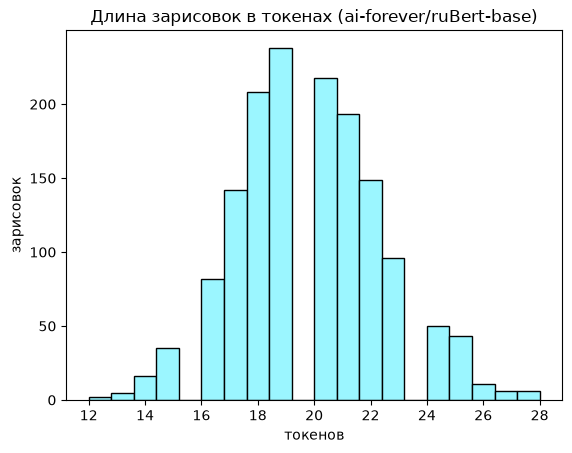

In [19]:
lengths = [len(tokenizer(t)["input_ids"]) for t in df["text"]]

plt.hist(lengths, bins=20, color="#9BF6FF", edgecolor="black")
plt.title(f"Длина зарисовок в токенах ({MODEL_NAME})")
plt.xlabel("токенов")
plt.ylabel("зарисовок")
plt.show()

### Туда и обратно

`decode` собирает текст обратно из номеров. Хороший токенизатор ничего не теряет.

In [20]:
sketch = df["text"][0]
ids = tokenizer(sketch)["input_ids"]

print("исходный:   ", sketch)
print("номера:     ", ids)
print("обратно:    ", tokenizer.decode(ids, skip_special_tokens=True))

исходный:    Солнце медленно опускается в море, по воде бежит дорожка света.
номера:      [101, 8072, 5114, 49532, 113, 4696, 121, 654, 9025, 26386, 54838, 6412, 126, 102]
обратно:     солнце медленно опускается в море, по воде бежит дорожка света.


### Батч: несколько фраз сразу

Модель обрабатывает фразы пачками (батчами), а в батче все строки должны быть одной длины. Короткие фразы дополняются токеном `[PAD]` (`padding=True`).

`attention_mask` подсказывает модели, где настоящие токены (1), а где заполнитель (0), чтобы она на него не смотрела.

In [21]:
batch = tokenizer(["Туман над рекой.", "Злость кипела внутри, и он хлопнул дверью."], padding=True)

for ids, mask in zip(batch["input_ids"], batch["attention_mask"]):
    print(tokenizer.convert_ids_to_tokens(ids))
    print("mask:", mask)
    print()

['[CLS]', 'туман', 'над', 'реко', '##и', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
mask: [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0]

['[CLS]', 'злость', 'кипела', 'внутри', ',', 'и', 'он', 'хлопнул', 'дверью', '.', '[SEP]']
mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]



## Модель до обучения

Считать будем на видеокарте, если она есть: там нейросети работают в десятки раз быстрее, чем на процессоре.

In [22]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

### Загружаем модель

`AutoModelForSequenceClassification` — это BERT плюс **голова классификации** сверху. Передаём:
- `num_labels` — сколько классов (цветов);
- `id2label` / `label2id` — наши словари, чтобы модель сама подписывала ответы цветами.

`torch.manual_seed` фиксирует случайные начальные веса головы, чтобы результат повторялся при перезапуске.

In [23]:
MODEL_NAME

'ai-forever/ruBert-base'

In [24]:
torch.manual_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(colors),
    id2label=id2label,
    label2id=label2id,
)
model = model.to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai-forever/ruBert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

### Что такое «голова» и какие головы выбросили

**Голова (head)** — это небольшой слой (или несколько слоёв) поверх энкодера, который превращает его векторы в ответ для конкретной задачи. Энкодер — общий «понимающий» модуль: он выдаёт вектор для каждого токена. Голова решает, *что именно* с этими векторами сделать. Одну и ту же BERT можно использовать для разных задач, меняя только голову.

При загрузке `transformers` печатает отчёт: какие веса из файла модели не пригодились (**UNEXPECTED**) и каких не хватило (**MISSING**).

#### Выброшенные головы (UNEXPECTED) — от предобучения

BERT предобучали на двух задачах, и для каждой у неё была своя голова:

1. **`cls.predictions` — голова Masked Language Modeling (MLM).** Угадывала слово, закрытое `[MASK]`. Для каждого токена брала его вектор (768 чисел), пропускала через слой `dense` + `LayerNorm` и затем через `decoder` — слой с выходом размером **со весь словарь** (120 138 чисел). Самое большое число — самое вероятное слово. Интересно, что веса `decoder` общие с таблицей эмбеддингов (*weight tying*): одна и та же матрица превращает номер токена в вектор на входе и вектор обратно в токен на выходе.
2. **`cls.seq_relationship` — голова Next Sentence Prediction (NSP).** Отвечала «да/нет»: идёт ли второе предложение сразу за первым. Это слой 768 → 2, на вход ему подавался вектор `[CLS]`.

Обе задачи нам не нужны: мы не угадываем слова и не сравниваем пары предложений. Поэтому эти головы просто не загрузились. Это нормально, и `transformers` прямо пишет, что такое можно игнорировать.

#### Новая голова (MISSING) — наша

**`classifier` — голова классификации.** Слой 768 → 10: на входе вектор всей фразы, на выходе 10 чисел (logits), по одному на цвет. В файле предобученной модели её не было, поэтому её веса созданы **случайно**. Именно поэтому до обучения модель отвечает наугад, и именно эту голову обучение настроит с нуля.

#### Как получается «вектор всей фразы»

Путь от текста до цвета в `BertForSequenceClassification`:

```
токены → эмбеддинги → 12 энкодер-блоков → вектор [CLS] → pooler → dropout → classifier → 10 logits
```

- **Вектор `[CLS]`** — после 12 блоков attention он вобрал информацию обо всей фразе (подробнее — в разделе про токенизатор).
- **`pooler`** — слой 768 → 768 с функцией `tanh` поверх вектора `[CLS]`. Его обучали вместе с NSP-головой, он есть в файле модели и загрузился. Его выход и идёт в классификатор.
- **`dropout`** при обучении случайно обнуляет 10% чисел, чтобы модель не полагалась на отдельные признаки и меньше переобучалась. При предсказании он выключен.

Всё, кроме `classifier`, загружено из предобученной модели — это её знания о языке. При дообучении мы будем немного подстраивать и их.

### Что внутри

Модель состоит из трёх частей: `bert` (энкодер), `dropout` и `classifier` (голова).

In [25]:
for name, part in model.named_children():
    n_params = sum(p.numel() for p in part.parameters())
    print(f"{name:12} {n_params:>12,} параметров")

bert          178,307,328 параметров
dropout                 0 параметров
classifier          7,690 параметров


Посчитаем отдельно, сколько параметров в таблице эмбеддингов, в энкодер-блоках и в голове:

In [26]:
def count_params(part):
    return sum(p.numel() for p in part.parameters())

print(f"всего:          {count_params(model):>12,}")
print(f"эмбеддинги:     {count_params(model.bert.embeddings):>12,}")
print(f"энкодер-блоки:  {count_params(model.bert.encoder):>12,}  ({len(model.bert.encoder.layer)} шт.)")
print(f"голова:         {count_params(model.classifier):>12,}")

всего:           178,315,018
эмбеддинги:       92,662,272
энкодер-блоки:    85,054,464  (12 шт.)
голова:                7,690


Голова крошечная: 768 × 10 весов + 10 сдвигов (bias) = 7 690 параметров на 178 миллионов. Но без неё модель не умеет отвечать «цветом».

Один энкодер-блок изнутри — те самые части из урока:
- `attention.self` с `query`, `key`, `value` — self-attention;
- `intermediate` + `output` — feed-forward сеть (768 → 3072 → 768);
- `LayerNorm` и `dropout` — служебные слои для стабильного обучения.

In [27]:
model.bert.encoder.layer[0]

BertLayer(
  (attention): BertAttention(
    (self): BertSelfAttention(
      (query): Linear(in_features=768, out_features=768, bias=True)
      (key): Linear(in_features=768, out_features=768, bias=True)
      (value): Linear(in_features=768, out_features=768, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (output): BertSelfOutput(
      (dense): Linear(in_features=768, out_features=768, bias=True)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (intermediate): BertIntermediate(
    (dense): Linear(in_features=768, out_features=3072, bias=True)
    (intermediate_act_fn): GELUActivation()
  )
  (output): BertOutput(
    (dense): Linear(in_features=3072, out_features=768, bias=True)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [28]:
model.bert.pooler

BertPooler(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (activation): Tanh()
)

In [29]:
model.classifier

Linear(in_features=768, out_features=10, bias=True)

### Одна зарисовка через необученную модель

- `return_tensors="pt"` — токенизатор возвращает тензоры PyTorch вместо списков;
- `model.eval()` — режим предсказания: отключает dropout, который нужен только при обучении;
- `torch.no_grad()` — не считать градиенты: при предсказании они не нужны, так быстрее и экономнее по памяти.

На выходе **logits** — 10 чисел, «оценки» каждого цвета. **Softmax** превращает их в вероятности (от 0 до 1, в сумме 1).

In [30]:
text = test_df["text"].iloc[0]
print(text, "→ правильный ответ:", test_df["color"].iloc[0])

inputs = tokenizer(text, return_tensors="pt").to(device)

model.eval()
with torch.no_grad():
    logits = model(**inputs).logits

probs = logits.softmax(dim=-1)

pd.DataFrame({"logit": logits[0].cpu(), "вероятность": probs[0].cpu()}, index=colors).round(3)

Ночная гроза прошла, и в лужах на асфальте дрожат отражения звёзд. → правильный ответ: синий


,logit,вероятность
красный,0.125,0.102
оранжевый,-0.475,0.056
жёлтый,0.076,0.097
зелёный,-0.190,0.075
голубой,0.173,0.107
синий,0.155,0.105
фиолетовый,0.747,0.190
коричневый,-0.013,0.089
белый,0.008,0.091
серый,-0.034,0.087


Все вероятности около 0.1: модель ничего не знает о цветах и «размазывает» ответ по всем десяти. Ответ — цвет с наибольшей вероятностью (**argmax**):

In [31]:
predicted_id = logits.argmax(dim=-1).item()
id2label[predicted_id]

'фиолетовый'

### Accuracy на тесте до обучения

Функция `predict` прогоняет список текстов батчами по 32 и возвращает номера предсказанных цветов. Она пригодится и после обучения.

- `padding=True` — выравниваем фразы в батче по длине;
- `truncation=True, max_length=32` — обрезаем слишком длинные (у нас таких нет, но так безопаснее).

In [32]:
def predict(texts, batch_size=32):
    model.eval()
    predictions = []
    for i in range(0, len(texts), batch_size):
        batch = tokenizer(
            texts[i : i + batch_size],
            padding=True,
            truncation=True,
            max_length=32,
            return_tensors="pt",
        ).to(device)
        with torch.no_grad():
            logits = model(**batch).logits
        predictions += logits.argmax(dim=-1).tolist()
    return predictions

In [33]:
test_pred = predict(test_df["text"].tolist())

accuracy_before = (pd.Series(test_pred, index=test_df.index) == test_df["label"]).mean()
print(f"accuracy до обучения: {accuracy_before:.0%}")

accuracy до обучения: 9%


Какие цвета модель выдаёт:

In [34]:
pd.Series(test_pred).map(id2label).value_counts()

фиолетовый    206
красный        13
жёлтый          6
Name: count, dtype: int64

Необученная модель почти на все фразы отвечает одним и тем же цветом: случайная голова сильнее «тянет» в одну сторону, чем различия между фразами. Правильно она угадывает только примеры этого цвета, поэтому accuracy около **10%** — столько же даёт угадывание наугад.

Это наша **точка отсчёта**. После обучения сравним с ней.

## Обучение

Учить будем через `Trainer` из `transformers`: он сам крутит цикл обучения — берёт батч, считает ошибку, обновляет веса, и так много раз.

### Данные для Trainer

`Trainer` ждёт датасет в формате библиотеки `datasets`, где у каждого примера есть:
- `input_ids` и `attention_mask` — результат токенизатора;
- `labels` — правильный ответ (номер цвета).

Переводим таблицы pandas в этот формат. Колонку `label` переименовываем в `labels`: так её называет модель.

In [35]:
train_ds = Dataset.from_pandas(train_df[["text", "label"]], preserve_index=False)
val_ds = Dataset.from_pandas(val_df[["text", "label"]], preserve_index=False)

train_ds = train_ds.rename_column("label", "labels")
val_ds = val_ds.rename_column("label", "labels")

train_ds

Dataset({
    features: ['text', 'labels'],
    num_rows: 1049
})

Токенизируем все тексты. `map` применяет функцию к датасету, `batched=True` — сразу пачками, так быстрее.

`padding="max_length"` дополняет каждую фразу `[PAD]` до 32 токенов. Так все примеры одной длины и их можно складывать в батч.

In [36]:
def tokenize(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=32)


train_ds = train_ds.map(tokenize, batched=True)
val_ds = val_ds.map(tokenize, batched=True)

train_ds

Map:   0%|          | 0/1049 [00:00<?, ? examples/s]

Map:   0%|          | 0/226 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1049
})

Как теперь выглядит один пример:

In [37]:
example = train_ds[0]

print("текст:  ", example["text"])
print("цвет:   ", id2label[example["labels"]])
print("токены: ", tokenizer.convert_ids_to_tokens(example["input_ids"]))
print("маска:  ", example["attention_mask"])

текст:   Соседка снова залила его балкон и не извинилась, и он стоял у двери, сжав кулаки.
цвет:    красный
токены:  ['[CLS]', 'соседка', 'снова', 'залила', 'его', 'балкон', 'и', 'не', 'извинилась', ',', 'и', 'он', 'стоял', 'у', 'двери', ',', 'сжав', 'кулаки', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
маска:   [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


### Метрика

После каждой эпохи `Trainer` прогонит validation и передаст в эту функцию logits модели и правильные ответы. Считаем accuracy — долю правильных ответов.

In [38]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {"accuracy": (predictions == labels).mean()}

### Модель

Загружаем модель заново, чтобы обучение всегда начиналось с одной и той же точки: предобученный BERT + случайная голова. Иначе повторный запуск ячейки с обучением продолжил бы учить уже обученную модель.

In [39]:
torch.manual_seed(42)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(colors),
    id2label=id2label,
    label2id=label2id,
).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai-forever/ruBert-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params we

### Настройки обучения

| Параметр | Значение | Что значит |
|---|---|---|
| `learning_rate` | 2e-5 | размер шага при обновлении весов. Маленький, чтобы не «сломать» знания BERT |
| `num_train_epochs` | 10 | сколько раз модель увидит весь train (максимум — лучшую эпоху выберем сами) |
| `per_device_train_batch_size` | 16 | примеров в одном шаге обучения |
| `weight_decay` | 0.01 | слегка тянет веса к нулю — мягкая защита от переобучения |
| `eval_strategy` | `"epoch"` | проверять на validation после каждой эпохи |
| `save_strategy` | `"epoch"` | сохранять модель после каждой эпохи (в папку `checkpoints/`) |
| `save_total_limit` | 1 | хранить на диске только лучшую и последнюю копию, каждая весит ~700 МБ |
| `load_best_model_at_end` | True | в конце загрузить эпоху с лучшим результатом на validation |
| `metric_for_best_model` | `"eval_loss"` | «лучшая» = с наименьшей ошибкой на validation |
| `report_to` | `"none"` | не отправлять логи во внешние сервисы |

Так мы не гадаем с числом эпох: если после 4-й эпохи модель начнёт переобучаться и ошибка на validation пойдёт вверх, в конце всё равно останется 4-я. Выбор делается по validation, поэтому тест остаётся честным.

In [40]:
args = TrainingArguments(
    output_dir="checkpoints",
    learning_rate=2e-5,
    num_train_epochs=10,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    report_to="none",
    seed=42,
)

In [41]:
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
)

### Учим

В таблице после каждой эпохи:
- **Training Loss** — ошибка на обучающих примерах. Должна падать;
- **Validation Loss** — ошибка на validation. Если она начинает расти, пока training loss падает, модель переобучается — запоминает train вместо того, чтобы обобщать;
- **Accuracy** — доля правильных ответов на validation.

In [42]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,2.186276,1.947283,0.460177
2,1.641749,1.511270,0.566372
3,1.126363,1.305022,0.579646
4,0.726304,1.209703,0.615044
5,0.435508,1.128324,0.637168
6,0.252878,1.145704,0.632743
7,0.149472,1.115008,0.646018
8,0.088366,1.179353,0.632743
9,0.061630,1.190401,0.646018
10,0.050063,1.207613,0.637168


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=660, training_loss=0.6718608794790326, metrics={'train_runtime': 72.9088, 'train_samples_per_second': 143.878, 'train_steps_per_second': 9.052, 'total_flos': 172514576290560.0, 'train_loss': 0.6718608794790326, 'epoch': 10.0})

### Графики обучения

`trainer.state.log_history` хранит всё, что `Trainer` записал во время обучения.

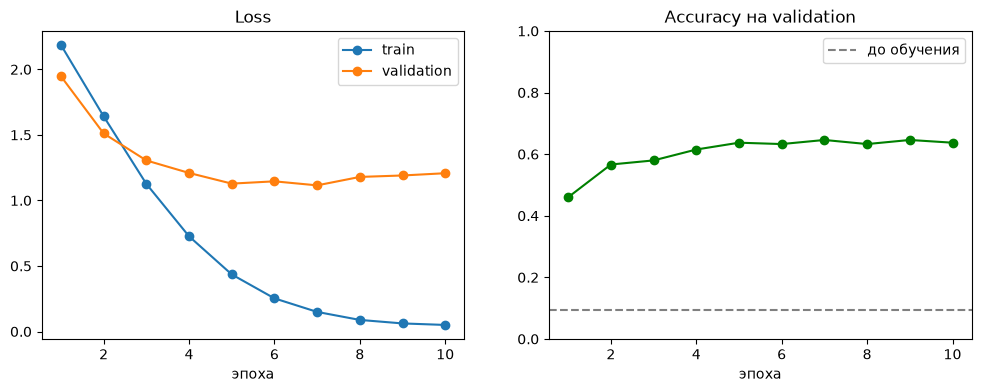

In [43]:
history = pd.DataFrame(trainer.state.log_history)

train_loss = history.dropna(subset=["loss"])
eval_logs = history.dropna(subset=["eval_loss"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_loss["epoch"], train_loss["loss"], "o-", label="train")
ax1.plot(eval_logs["epoch"], eval_logs["eval_loss"], "o-", label="validation")
ax1.set_title("Loss")
ax1.set_xlabel("эпоха")
ax1.legend()

ax2.plot(eval_logs["epoch"], eval_logs["eval_accuracy"], "o-", color="green")
ax2.axhline(accuracy_before, color="gray", linestyle="--", label="до обучения")
ax2.set_title("Accuracy на validation")
ax2.set_xlabel("эпоха")
ax2.set_ylim(0, 1)
ax2.legend()

plt.show()

### Сравниваем с точкой отсчёта

`load_best_model_at_end` уже загрузил лучшую эпоху. Какая это была:

In [44]:
eval_logs = pd.DataFrame(trainer.state.log_history).dropna(subset=["eval_loss"])
best = eval_logs.loc[eval_logs["eval_loss"].idxmin()]

print(f"лучшая эпоха: {best['epoch']:.0f}")
print(f"validation loss: {best['eval_loss']:.3f}, accuracy: {best['eval_accuracy']:.0%}")

лучшая эпоха: 7
validation loss: 1.115, accuracy: 65%


Теперь — **тот самый единственный замер на тесте**. Та же функция `predict`, что и до обучения.

In [45]:
test_pred = predict(test_df["text"].tolist())

accuracy_after = (pd.Series(test_pred, index=test_df.index) == test_df["label"]).mean()

print(f"accuracy до обучения:    {accuracy_before:.0%}")
print(f"accuracy после обучения: {accuracy_after:.0%}")

accuracy до обучения:    9%
accuracy после обучения: 66%


## Диагностика

Одно число accuracy мало что говорит. Разберёмся, **где** модель ошибается.

### Train, validation и test

- если на train почти 100%, а на validation/test заметно меньше — модель **переобучилась**: запомнила обучающие фразы наизусть;
- если и на train низко — **недоучилась**: ей не хватает обучения или сама задача слишком шумная.

In [46]:
def accuracy(part_df):
    pred = predict(part_df["text"].tolist())
    return (pd.Series(pred, index=part_df.index) == part_df["label"]).mean()


pd.Series({
    "train": accuracy(train_df),
    "validation": accuracy(val_df),
    "test": accuracy(test_df),
}, name="accuracy").round(3)

train         0.999
validation    0.646
test          0.662
Name: accuracy, dtype: float64

### Матрица ошибок

Строка — правильный цвет, столбец — что ответила модель. На диагонали правильные ответы, вне диагонали ошибки: например, число в строке «голубой» и столбце «синий» — сколько голубых зарисовок модель назвала синими.

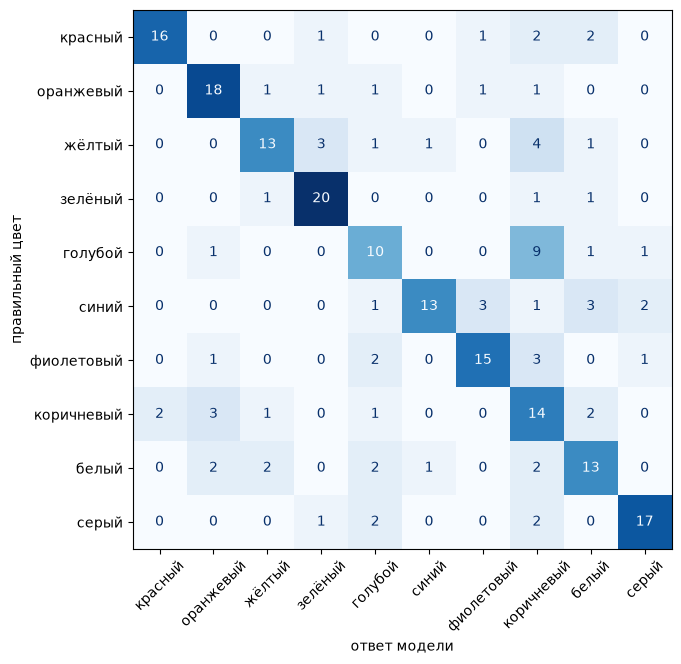

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay

test_df["pred"] = predict(test_df["text"].tolist())
test_df["pred_color"] = test_df["pred"].map(id2label)
test_df["correct"] = test_df["pred"] == test_df["label"]

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    test_df["color"],
    test_df["pred_color"],
    labels=colors,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_xlabel("ответ модели")
ax.set_ylabel("правильный цвет")
plt.show()

Самые частые пары «правильный → ответ модели» среди ошибок:

In [48]:
errors = test_df[~test_df["correct"]]
errors.groupby(["color", "pred_color"]).size().sort_values(ascending=False).head(10)

color       pred_color
голубой     коричневый    9
жёлтый      коричневый    4
            зелёный       3
синий       белый         3
коричневый  оранжевый     3
фиолетовый  коричневый    3
синий       фиолетовый    3
белый       коричневый    2
            оранжевый     2
            жёлтый        2
dtype: int64

### Сцены и эмоции отдельно

Две гипотезы, какая из частей труднее:
- **эмоции**: связь «любовь → оранжевый» условная, её нужно выучить из примеров;
- **сцены**: чтобы понять, что клубника красная, а сапфир синий, нужно знать цвета предметов. BERT учился только на тексте и цвета вещей знает лишь настолько, насколько о них пишут.

Проверим, какая из гипотез верна.

In [49]:
test_df.groupby("type")["correct"].mean().round(3)

type
сцена     0.478
эмоция    0.855
Name: correct, dtype: float64

По каждому цвету отдельно:

In [50]:
test_df.groupby(["color", "type"])["correct"].mean().unstack().loc[colors].round(2)

type,сцена,эмоция
color,,
красный,0.45,1.00
оранжевый,0.67,0.91
жёлтый,0.33,0.82
зелёный,0.83,0.91
голубой,0.55,0.36
синий,0.50,0.64
фиолетовый,0.36,1.00
коричневый,0.25,1.00
белый,0.27,0.91


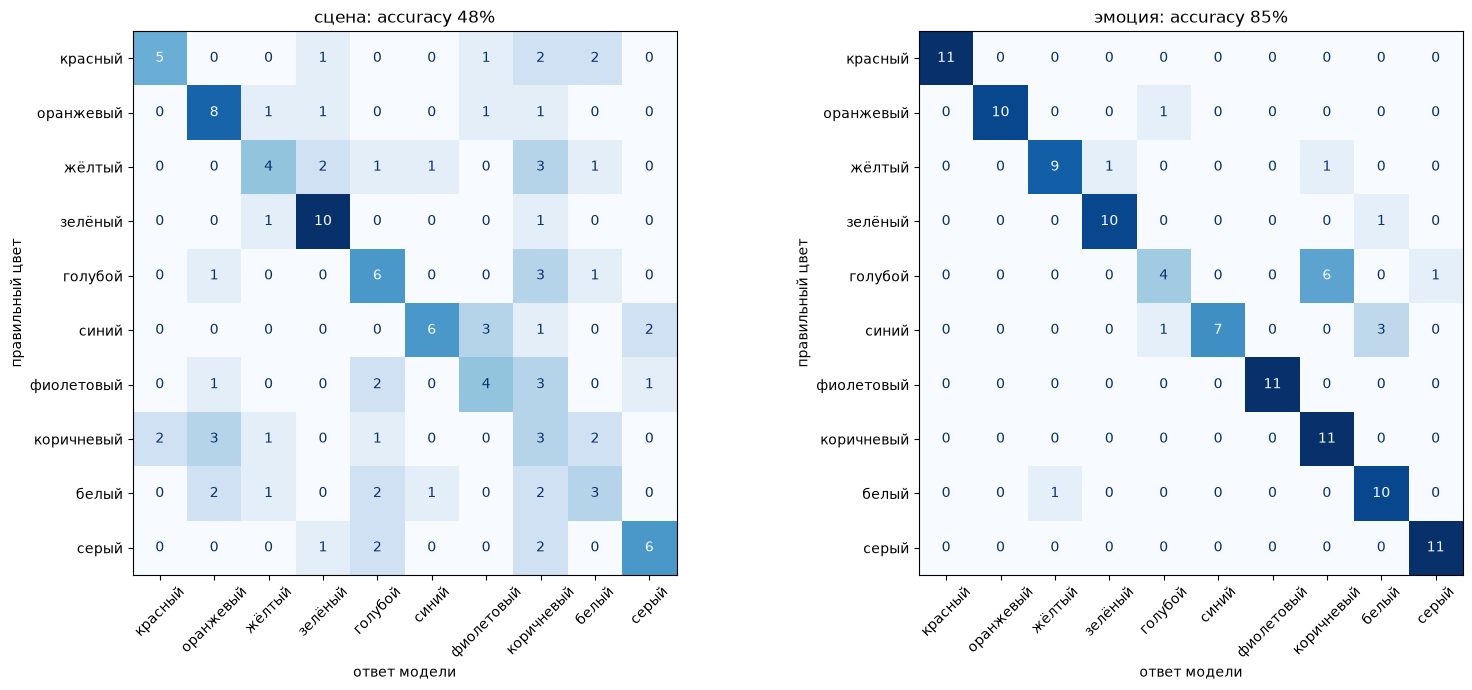

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, kind in zip(axes, ["сцена", "эмоция"]):
    part = test_df[test_df["type"] == kind]
    ConfusionMatrixDisplay.from_predictions(
        part["color"],
        part["pred_color"],
        labels=colors,
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"{kind}: accuracy {part['correct'].mean():.0%}")
    ax.set_xlabel("ответ модели")
    ax.set_ylabel("правильный цвет")

plt.tight_layout()
plt.show()

### Примеры ошибок

Полезно почитать глазами: иногда модель ошибается, а иногда спорна сама разметка.

In [52]:
pd.set_option("display.max_colwidth", 200)
errors[["text", "type", "color", "pred_color"]].sample(min(15, len(errors)), random_state=42)

,text,type,color,pred_color
952,Старинный сапфир в оправе лежит в бархатной коробке на витрине ювелирного магазина.,сцена,синий,фиолетовый
1474,"Зола в печи остыла за ночь, и в доме пахнет холодным кирпичом и золой.",сцена,серый,коричневый
530,"Пожарная машина стоит у ворот депо, и мальчишки разглядывают лестницу на крыше.",сцена,красный,фиолетовый
310,"Ночная гроза прошла, и в лужах на асфальте дрожат отражения звёзд.",сцена,синий,фиолетовый
1461,"В больничной палате тихо гудит лампа, и накрахмаленная простыня пахнет чем-то стерильным.",сцена,белый,синий
384,"Тёртый шоколад сыплется на торт, и ложка оставляет вязкий след на блюде.",сцена,коричневый,оранжевый
675,"Он переживал за друга весь день и наконец позвонил, и голос дрогнул от заботы.",эмоция,оранжевый,голубой
347,"Ирисы в вазе стоят давно, и лепестки уже чуть поникли к вечеру.",сцена,фиолетовый,голубой
614,"Закатное небо за окном поезда, полосы облаков горят, и пассажиры замолкают у окон.",сцена,оранжевый,жёлтый
437,"Журавли тянутся в небе клином, и их крики долетают до самой земли.",сцена,белый,голубой


## Эксперименты

Два вопроса:
1. **Насколько важен размер модели?** Сравним ruBert-base (178M параметров) с маленькой `cointegrated/rubert-tiny2` (29M).
2. **Насколько стабилен результат?** Одна accuracy из одного запуска может оказаться удачей или неудачей. Обучим каждую модель **5 раз с разными seed** и посмотрим на среднее и разброс.

Что меняет seed:
- разбиение на train и validation (test всегда один и тот же — так сравнение честное);
- случайные начальные веса головы классификации;
- порядок примеров при обучении.

**Learning rate.** Для ruBert-base оставляем `2e-5`. Маленьким моделям обычно нужен шаг побольше: на `2e-5` rubert-tiny2 не успевает обучиться за 10 эпох. Для неё взят `1e-4` — он дал лучший loss на **validation** среди `2e-5`, `5e-5`, `1e-4`, `2e-4`, `3e-4`. Тест при подборе не использовался.

Всего 10 обучений, это займёт около 7 минут.

### Освобождаем видеокарту

Основная модель и `trainer` занимают в памяти видеокарты около 3 ГБ: веса, градиенты и состояние оптимизатора. Вместе с моделью эксперимента это почти 8 ГБ, видеокарта может не выдержать. Основная модель дальше не нужна, удаляем её.

После этой ячейки функция `predict` из разделов выше работать не будет: она использует удалённую `model`. Чтобы вернуться к ним, перезапусти ноутбук.

In [53]:
import gc

del model, trainer
gc.collect()              # окончательно удалить объекты из памяти Python
torch.cuda.empty_cache()  # вернуть освободившуюся память видеокарты

print(f"занято памяти видеокарты: {torch.cuda.memory_allocated() / 1e9:.2f} ГБ")

занято памяти видеокарты: 0.03 ГБ


### Функция одного эксперимента

Делает всё то же, что мы делали выше по шагам: разбивает данные, токенизирует, загружает модель, обучает с выбором лучшей эпохи по validation и считает accuracy на тесте — общую и отдельно для сцен и эмоций. В конце удаляет модель из памяти видеокарты и сохранённые копии с диска.

In [54]:
import shutil
import time

import datasets

from transformers import PrinterCallback
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()   # не печатать отчёт о весах при каждой загрузке
hf_logging.disable_progress_bar()  # и полоски сохранения модели
datasets.disable_progress_bars()   # и полоски токенизации датасетов


def run_experiment(model_name, learning_rate, seed):
    # 1. Своё разбиение train/validation для каждого seed. Test всегда один и тот же.
    exp_train_df, exp_val_df = train_test_split(
        train_val_df,
        test_size=0.15 / 0.85,
        stratify=train_val_df["group"],
        random_state=seed,
    )

    # 2. Токенизатор этой модели и датасеты.
    exp_tokenizer = AutoTokenizer.from_pretrained(model_name)

    def to_dataset(part):
        ds = Dataset.from_pandas(part[["text", "label"]], preserve_index=False)
        ds = ds.rename_column("label", "labels")
        return ds.map(
            lambda batch: exp_tokenizer(batch["text"], padding="max_length", truncation=True, max_length=32),
            batched=True,
        )

    # 3. Модель: предобученный энкодер + новая случайная голова.
    torch.manual_seed(seed)
    exp_model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(colors),
        id2label=id2label,
        label2id=label2id,
    ).to(device)
    n_params = count_params(exp_model)

    # 4. Обучение с выбором лучшей эпохи по validation.
    exp_args = TrainingArguments(
        output_dir="checkpoints/experiment",
        learning_rate=learning_rate,
        num_train_epochs=10,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        report_to="none",
        seed=seed,
        disable_tqdm=True,
    )
    exp_trainer = Trainer(
        model=exp_model,
        args=exp_args,
        train_dataset=to_dataset(exp_train_df),
        eval_dataset=to_dataset(exp_val_df),
        compute_metrics=compute_metrics,
    )
    exp_trainer.remove_callback(PrinterCallback)  # не печатать логи каждой эпохи

    start = time.time()
    exp_trainer.train()
    seconds = time.time() - start

    # 5. Оценка: validation и test (лучшая эпоха уже загружена).
    val_accuracy = exp_trainer.evaluate()["eval_accuracy"]
    test_logits = exp_trainer.predict(to_dataset(test_df)).predictions
    correct = test_logits.argmax(axis=-1) == test_df["label"].values
    is_scene = (test_df["type"] == "сцена").values

    # 6. Освобождаем память видеокарты и место на диске.
    del exp_model, exp_trainer
    torch.cuda.empty_cache()
    shutil.rmtree("checkpoints/experiment", ignore_errors=True)

    return {
        "model": model_name,
        "seed": seed,
        "params_M": n_params / 1e6,
        "val": val_accuracy,
        "test": correct.mean(),
        "test_сцены": correct[is_scene].mean(),
        "test_эмоции": correct[~is_scene].mean(),
        "seconds": seconds,
    }

### Запускаем

Каждая строка — одно обучение с нуля.

In [55]:
experiments = [
    ("ai-forever/ruBert-base", 2e-5),
    ("cointegrated/rubert-tiny2", 1e-4),
]
seeds = [0, 1, 2, 3, 4]

results = []
for model_name, learning_rate in experiments:
    for seed in seeds:
        r = run_experiment(model_name, learning_rate, seed)
        results.append(r)
        print(f"{model_name:28} seed={seed}  val={r['val']:.1%}  test={r['test']:.1%}  ({r['seconds']:.0f} с)")

results_df = pd.DataFrame(results)

ai-forever/ruBert-base       seed=0  val=67.3%  test=64.4%  (72 с)


ai-forever/ruBert-base       seed=1  val=67.7%  test=63.6%  (73 с)


ai-forever/ruBert-base       seed=2  val=65.9%  test=65.8%  (73 с)


ai-forever/ruBert-base       seed=3  val=65.9%  test=60.9%  (73 с)


ai-forever/ruBert-base       seed=4  val=65.9%  test=64.4%  (72 с)


cointegrated/rubert-tiny2    seed=0  val=55.8%  test=56.9%  (12 с)


cointegrated/rubert-tiny2    seed=1  val=57.1%  test=56.9%  (12 с)


cointegrated/rubert-tiny2    seed=2  val=55.8%  test=60.0%  (12 с)


cointegrated/rubert-tiny2    seed=3  val=54.4%  test=57.8%  (12 с)


cointegrated/rubert-tiny2    seed=4  val=54.0%  test=53.3%  (12 с)


### Итог: среднее ± разброс

**std** (стандартное отклонение) показывает, насколько результат скачет от запуска к запуску. Если разница между моделями меньше разброса, по одному запуску нельзя сказать, какая лучше.

In [56]:
metrics = ["test", "test_сцены", "test_эмоции", "val"]

summary = results_df.groupby("model")[metrics].agg(["mean", "std"]).round(3)
summary[("params_M", "")] = results_df.groupby("model")["params_M"].first().round(0)
summary[("seconds", "")] = results_df.groupby("model")["seconds"].mean().round(0)
summary

test        test_сцены        test_эмоции         \
                            mean    std       mean    std        mean    std   
model                                                                          
ai-forever/ruBert-base     0.638  0.018      0.437  0.007       0.849  0.031   
cointegrated/rubert-tiny2  0.570  0.024      0.412  0.018       0.735  0.041   

                             val        params_M seconds  
                            mean    std                   
model                                                     
ai-forever/ruBert-base     0.665  0.009    178.0    73.0  
cointegrated/rubert-tiny2  0.554  0.012     29.0    12.0

Те же цифры коротко:

In [57]:
for model_name, part in results_df.groupby("model"):
    print(f"{model_name:28} test accuracy {part['test'].mean():.1%} ± {part['test'].std():.1%}")

ai-forever/ruBert-base       test accuracy 63.8% ± 1.8%
cointegrated/rubert-tiny2    test accuracy 57.0% ± 2.4%


Каждая точка — один запуск, чёрная черта — среднее:

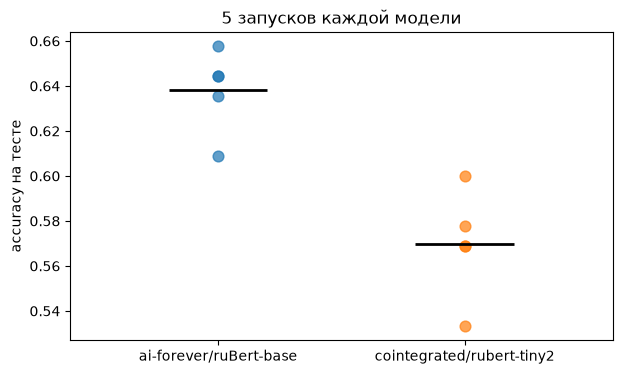

In [58]:
fig, ax = plt.subplots(figsize=(7, 4))

for i, (model_name, part) in enumerate(results_df.groupby("model")):
    ax.scatter([i] * len(part), part["test"], s=60, alpha=0.7)
    ax.hlines(part["test"].mean(), i - 0.2, i + 0.2, color="black", linewidth=2)

ax.set_xticks(range(results_df["model"].nunique()), sorted(results_df["model"].unique()))
ax.set_ylabel("accuracy на тесте")
ax.set_title("5 запусков каждой модели")
ax.set_xlim(-0.6, 1.6)
plt.show()